<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="40"/>

# Senegal's next six afternoons at 9 km 🌡️
### ECMWF free & open data · IFS 9 km · no account needed
*Made for SEWA, Strengthening Early Warnings for Africa*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/heat_forecast.ipynb)

ECMWF's 9 km forecast (IFS) is **open data**: no login, no fee. This notebook downloads 2 m temperature for
15:00 UTC (15:00 in Dakar) on each of the next six days, prints how hot each afternoon gets in six Senegalese towns,
and maps the hottest one.

**What you need:** a Google account (to use Colab). No other account, no fee, nothing to install. Everything runs on Google's computers: the data is downloaded there, not to your phone
or laptop, so a slow or mobile connection is fine.

| Data | What this notebook uses | Licence |
|---|---|---|
| ECMWF IFS forecast, 9 km (0.1°) | 2 m temperature at 15 UTC, six days, latest run | CC BY 4.0, open data |

**Tools:** [earthkit](https://earthkit.ecmwf.int), ECMWF's free, open-source Python tools for weather and climate data.

*Press **Runtime → Run all**. The first run takes a few minutes, mostly installing the tools.*

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes ~1 minute.
%pip install -q "earthkit-data[ecmwf-opendata]" earthkit-plots ecmwf-opendata

In [2]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np
from ecmwf.opendata import Client

## 1 · Choose the area

In [3]:
AREA  = [17.5, -18.5, 11.5, -10.5]          # north, west, south, east: Senegal and The Gambia
STEPS = [15 + 24 * d for d in range(6)]     # 15 UTC today and the next five days (Dakar is on UTC)
CITIES = [("Dakar", 14.716, -17.467), ("Saint-Louis", 16.018, -16.489), ("Touba", 14.850, -15.883),
          ("Tambacounda", 13.771, -13.667), ("Ziguinchor", 12.583, -16.272), ("Kédougou", 12.557, -12.174)]

def label_cities(ax):
    for name, la, lo in CITIES:
        ax.scatter([lo], [la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10,
                   transform=ccrs.PlateCarree())
        ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Get the 9 km forecast (ECMWF open data)

In [4]:
for SOURCE in ("ecmwf", "aws", "google"):      # ECMWF first, then the cloud mirrors if it is busy
    try:
        result = Client(SOURCE).retrieve(time=0, step=STEPS, stream="oper", type="fc", levtype="sfc",
                                         param="2t", resol="0p1", target="t2m.grib2")   # resol="0p1" = 9 km
        break
    except Exception as err:
        print(f"{SOURCE} did not answer ({type(err).__name__}), trying the next mirror")
run = result.datetime
x = ekd.from_source("file", "t2m.grib2").to_xarray()
x = x.assign_coords(longitude=((x.longitude + 180) % 360) - 180).sortby("longitude")
x = x.sel(latitude=slice(AREA[0] + 0.5, AREA[2] - 0.5), longitude=slice(AREA[1] - 0.5, AREA[3] + 0.5))  # small margin
t2m = x[list(x.data_vars)[0]] - 273.15                                            # kelvin -> °C
sdim = [d for d in t2m.dims if d not in ("latitude", "longitude")][0]
print(f"Forecast run {run:%A %d %B %Y} 00 UTC")
for k, s in enumerate(STEPS):
    v = run + dt.timedelta(hours=s)
    towns = "  ".join(f"{n} {float(t2m.isel({sdim: k}).sel(latitude=la, longitude=lo, method='nearest')):.0f}°"
                      for n, la, lo in CITIES)
    print(f"  {v:%a %d %b} 15 UTC   {towns}")
hot = int(t2m.mean(["latitude", "longitude"]).argmax())                            # the hottest afternoon
day = run + dt.timedelta(hours=STEPS[hot])

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


Forecast run Thursday 19 November 2026 00 UTC
  Thu 19 Nov 15 UTC   Dakar 29°  Saint-Louis 29°  Touba 36°  Tambacounda 35°  Ziguinchor 32°  Kédougou 30°
  Fri 20 Nov 15 UTC   Dakar 30°  Saint-Louis 29°  Touba 37°  Tambacounda 36°  Ziguinchor 34°  Kédougou 31°
  Sat 21 Nov 15 UTC   Dakar 33°  Saint-Louis 33°  Touba 38°  Tambacounda 38°  Ziguinchor 35°  Kédougou 33°
  Sun 22 Nov 15 UTC   Dakar 33°  Saint-Louis 33°  Touba 38°  Tambacounda 38°  Ziguinchor 34°  Kédougou 34°
  Mon 23 Nov 15 UTC   Dakar 32°  Saint-Louis 30°  Touba 37°  Tambacounda 37°  Ziguinchor 35°  Kédougou 34°
  Tue 24 Nov 15 UTC   Dakar 31°  Saint-Louis 27°  Touba 38°  Tambacounda 37°  Ziguinchor 35°  Kédougou 34°


## 3 · Map the hottest afternoon

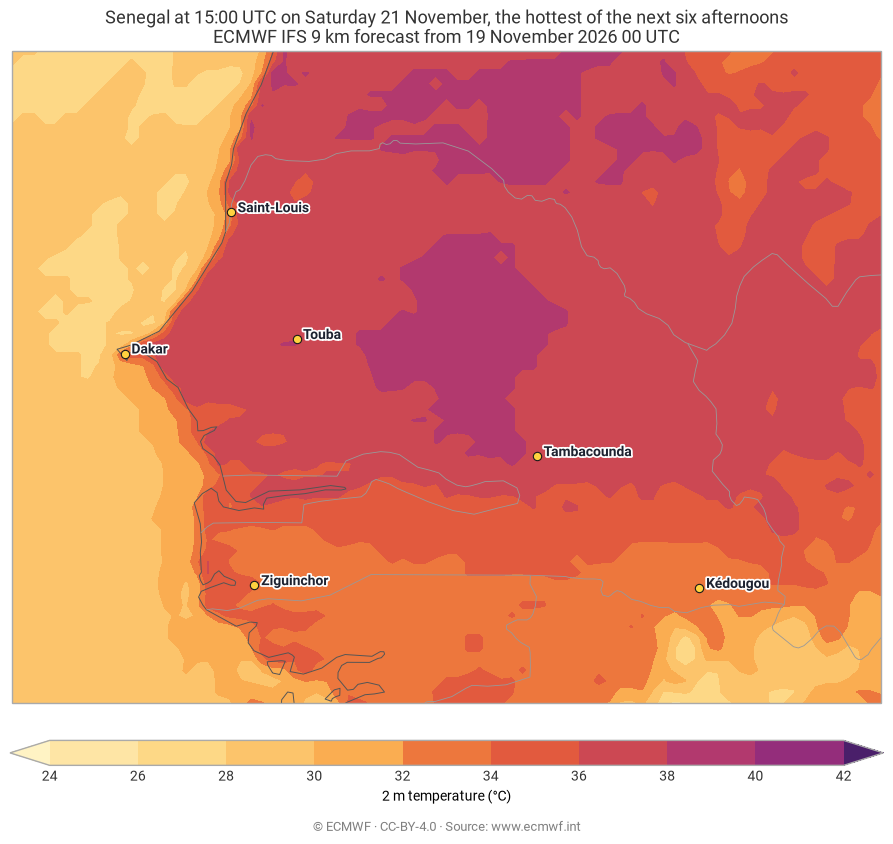

In [5]:
style = ekp.styles.Style(levels=[24, 26, 28, 30, 32, 34, 36, 38, 40, 42], colors=["#fff3c4", "#fdd27a", "#f99a3c", "#e0543e", "#a3307e", "#4a1f6a"], extend="both")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(11, 8))
chart.contourf(t2m.isel({sdim: hot}), style=style)
chart.coastlines(linewidth=0.7); chart.borders(linewidth=0.6)
label_cities(chart.ax)
chart.legend(label="2 m temperature (°C)")
chart.title(f"Senegal at 15:00 UTC on {day:%A %d %B}, the hottest of the next six afternoons\n"
            f"ECMWF IFS 9 km forecast from {run:%d %B %Y} 00 UTC", fontsize=13)
chart.attribution("© ECMWF · CC-BY-4.0 · Source: www.ecmwf.int")
chart.save("heat_forecast.png")
chart.show()

## 4 · Your turn 🌍

- **Night-time:** change `15` to `3` in `STEPS` for 03 UTC, the coolest part of the night.
- **The wind:** add `"10u", "10v"` to `param` and draw arrows with `chart.ax.quiver`.
- **Anywhere else:** change `AREA`, for example `[16, -6, 9, 3]` for Burkina Faso.

### Data & licence
ECMWF Open Data is free under **Creative Commons CC-BY-4.0**:
`© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`. No account, no key.

[ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data) · [earthkit](https://earthkit.ecmwf.int)